# 02 — Baseline

**Objetivo:** construir um primeiro modelo simples, avaliado com o esquema de validação definido na EDA, para servir de **régua**: as próximas melhorias só contam se superarem este resultado.

> Como na EDA, só o treino (meses 0–5) é usado. O teste continua intocado.

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd

# Caminhos portáveis (mesmo padrão dos notebooks anteriores)
EM_COLAB = "google.colab" in sys.modules
if EM_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    RAIZ = Path("/content/drive/MyDrive/fraude-abertura-conta")
else:
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAIZ = Path(os.getenv("FRAUDE_RAIZ", RAIZ))
DATA_DIR = RAIZ / "data"

treino = pd.read_parquet(DATA_DIR / "train.parquet")
assert treino["month"].between(0, 5).all(), "train.parquet deveria conter apenas os meses 0–5"
print(f"{len(treino):,} linhas")

794,989 linhas


## 1. Validação temporal

Seguindo a decisão da EDA (seção 8), usamos **janela crescente**: cada fold treina em todos os meses anteriores e valida no mês seguinte. Assim o modelo sempre é avaliado em dados **do futuro** em relação ao que viu — como acontece em produção.

In [2]:
# (meses de treino, mês de validação)
FOLDS = [([0, 1, 2], 3), ([0, 1, 2, 3], 4), ([0, 1, 2, 3, 4], 5)]


def gerar_folds(df, folds=FOLDS):
    """Para cada fold, devolve os meses e os índices das linhas de treino e de validação."""
    for meses_treino, mes_val in folds:
        idx_tr = df.index[df["month"].isin(meses_treino)]
        idx_val = df.index[df["month"] == mes_val]
        yield meses_treino, mes_val, idx_tr, idx_val


linhas = []
for meses_tr, mes_val, idx_tr, idx_val in gerar_folds(treino):
    linhas.append({
        "fold": f"{meses_tr[0]}–{meses_tr[-1]} → {mes_val}",
        "linhas treino": len(idx_tr),
        "linhas validação": len(idx_val),
        "% fraude treino": 100 * treino.loc[idx_tr, "fraud_bool"].mean(),
        "% fraude validação": 100 * treino.loc[idx_val, "fraud_bool"].mean(),
    })
tabela_folds = pd.DataFrame(linhas).set_index("fold")
tabela_folds.style.format(precision=2, thousands=".", decimal=",")

,linhas treino,linhas validação,% fraude treino,% fraude validação
fold,,,,
0–2 → 3,397.039,150.936,"0,98","0,92"
0–3 → 4,547.975,127.691,"0,97","1,14"
0–4 → 5,675.666,119.323,"1,00","1,18"


## 2. Métricas

Definidas na EDA (seção 1): **Recall a 5% de FPR** (principal), **PR-AUC** e **ROC AUC**. Antes de usar a função, ela é testada em dois casos com resposta conhecida: scores aleatórios e scores perfeitos.

In [3]:
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve

FPR_ALVO = 0.05


def recall_a_fpr(y, score, fpr_alvo=FPR_ALVO):
    """Maior recall (TPR) alcançável sem passar de `fpr_alvo` de falsos positivos."""
    fpr, tpr, _ = roc_curve(y, score)
    return tpr[fpr <= fpr_alvo].max()


def avaliar(y, score):
    """As três métricas do projeto para um vetor de rótulos e um de scores."""
    return {
        "recall@5%FPR": recall_a_fpr(y, score),
        "PR-AUC": average_precision_score(y, score),
        "ROC AUC": roc_auc_score(y, score),
    }

In [4]:
y_teste_metrica = treino.loc[treino["month"] == 5, "fraud_bool"].to_numpy()
rng = np.random.default_rng(42)

checagem = pd.DataFrame({
    "aleatório": avaliar(y_teste_metrica, rng.random(len(y_teste_metrica))),
    "perfeito": avaliar(y_teste_metrica, y_teste_metrica.astype(float)),
}).T
checagem["taxa de fraude"] = y_teste_metrica.mean()
checagem.style.format(precision=3, decimal=",")

,recall@5%FPR,PR-AUC,ROC AUC,taxa de fraude
aleatório,"0,050","0,012","0,514","0,012"
perfeito,"1,000","1,000","1,000","0,012"


## 3. Baseline ingênuo: uma variável como score

A régua mínima: usar o `credit_risk_score` diretamente como score de suspeita, sem nenhum treino. Foi a variável contínua com maior contraste de fraude entre decis na EDA (~6×).

In [5]:
def validar(modelo, df=treino, alvo="fraud_bool"):
    """Avalia `modelo` nos folds temporais.

    `modelo` é uma função que recebe (dados_treino, dados_validacao) e devolve
    um score por linha da validação. Retorna as métricas por fold, a média e o desvio.
    """
    linhas = []
    for meses_tr, mes_val, idx_tr, idx_val in gerar_folds(df):
        score = modelo(df.loc[idx_tr], df.loc[idx_val])
        metricas = avaliar(df.loc[idx_val, alvo], score)
        linhas.append({"fold": f"{meses_tr[0]}–{meses_tr[-1]} → {mes_val}", **metricas})

    resultado = pd.DataFrame(linhas).set_index("fold")
    resultado.loc["média"] = resultado.mean()
    resultado.loc["desvio padrão"] = resultado.iloc[:-1].std()
    return resultado

In [6]:
def regra_credit_score(df_tr, df_val):
    # Não usa df_tr: a regra não aprende nada com os dados
    return df_val["credit_risk_score"].to_numpy()


res_ingenuo = validar(regra_credit_score)
res_ingenuo.style.format(precision=3, decimal=",")

,recall@5%FPR,PR-AUC,ROC AUC
fold,,,
0–2 → 3,"0,228","0,027","0,706"
0–3 → 4,"0,218","0,032","0,688"
0–4 → 5,"0,193","0,031","0,659"
média,"0,213","0,030","0,685"
desvio padrão,"0,018","0,003","0,024"


## 4. Pré-processamento

Duas etapas, separadas de propósito:
1. **Limpeza sem estado** (linha a linha, sem aprender nada dos dados): códigos de ausência viram `NaN`, `velocity_6h` negativo vira 0, colunas descartadas. Pode ser aplicada em qualquer conjunto sem risco de vazamento.
2. **Transformações com estado** (mediana, padronização, one-hot): aprendem com os dados, então ficam dentro de um `Pipeline` que é ajustado **apenas no treino de cada fold**.

In [7]:
ALVO = "fraud_bool"
DESCARTAR = ["device_fraud_count", "month"]

CATEGORICAS = ["payment_type", "employment_status", "housing_status", "source", "device_os"]
BINARIAS = ["email_is_free", "phone_home_valid", "phone_mobile_valid",
            "has_other_cards", "foreign_request", "keep_alive_session"]
CAUDA_LONGA = ["days_since_request", "session_length_in_minutes",
               "bank_branch_count_8w", "prev_address_months_count"]
NUMERICAS = [c for c in treino.columns if c not in [ALVO] + DESCARTAR + CATEGORICAS + BINARIAS + CAUDA_LONGA]

# Códigos de ausência, segundo o dicionário de dados (EDA, seção 2)
AUSENTE_MENOS_1 = ["prev_address_months_count", "current_address_months_count", "bank_months_count",
                   "session_length_in_minutes", "device_distinct_emails_8w"]
AUSENTE_NEGATIVO = ["intended_balcon_amount"]

# Colunas que, pelo significado, não podem ser negativas (contagens, tempos, velocidades, valores).
# Exceção: credit_risk_score, cuja escala inclui negativos legítimos (EDA, seção 2).
NAO_NEGATIVAS = [c for c in NUMERICAS + CAUDA_LONGA if c != "credit_risk_score"]


def limpar(df):
    """Limpeza sem estado: não aprende nada dos dados, então não há risco de vazamento."""
    out = df.drop(columns=DESCARTAR + [ALVO], errors="ignore").copy()
    for c in AUSENTE_MENOS_1:
        out[c] = out[c].where(out[c] != -1)
    for c in AUSENTE_NEGATIVO:
        out[c] = out[c].where(out[c] >= 0)
    # Defesa contra artefatos da geração sintética (no treino, só velocity_6h tinha negativos):
    # garante que nenhum valor impossível chegue ao log1p em meses futuros
    out[NAO_NEGATIVAS] = out[NAO_NEGATIVAS].clip(lower=0)
    return out


print(f"{len(NUMERICAS)} numéricas, {len(CAUDA_LONGA)} de cauda longa, "
      f"{len(BINARIAS)} binárias, {len(CATEGORICAS)} categóricas")

14 numéricas, 4 de cauda longa, 6 binárias, 5 categóricas


In [8]:
X_limpo = limpar(treino)
ausentes = 100 * X_limpo.isna().mean()

print(f"Formato: {X_limpo.shape}")
print(f"Negativos restantes nas colunas não negativas: {int((X_limpo[NAO_NEGATIVAS] < 0).sum().sum())}")
print("\n% de ausentes (NaN) por coluna:")
print(ausentes[ausentes > 0].sort_values(ascending=False).round(2).to_string())

Formato: (794989, 29)
Negativos restantes nas colunas não negativas: 0

% de ausentes (NaN) por coluna:
intended_balcon_amount          73.70
prev_address_months_count       71.50
bank_months_count               25.10
current_address_months_count     0.38
session_length_in_minutes        0.19
device_distinct_emails_8w        0.04


### 4.1 Transformações com estado

Montadas num `ColumnTransformer`: cada grupo de colunas recebe seu tratamento. Ele é **ajustado (`fit`) só no treino de cada fold** e depois apenas **aplicado (`transform`)** na validação — assim mediana, média, desvio e categorias são aprendidos sem olhar a validação.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

LIMIAR_CATEGORIA_RARA = 2_000  # categorias com menos linhas que isso viram "infrequent"


def montar_preprocessador():
    """Pré-processamento com estado. Um objeto novo por fold, para nada vazar entre folds."""
    numericas = make_pipeline(
        SimpleImputer(strategy="median", add_indicator=True),
        StandardScaler(),
    )
    cauda_longa = make_pipeline(
        FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
        SimpleImputer(strategy="median", add_indicator=True),
        StandardScaler(),
    )
    categoricas = OneHotEncoder(
        min_frequency=LIMIAR_CATEGORIA_RARA,
        handle_unknown="infrequent_if_exist",
        sparse_output=False,
    )
    preprocessador = ColumnTransformer(
        [
            ("num", numericas, NUMERICAS),
            ("cauda", cauda_longa, CAUDA_LONGA),
            ("bin", "passthrough", BINARIAS),
            ("cat", categoricas, CATEGORICAS),
        ],
        verbose_feature_names_out=False,
    )
    return preprocessador.set_output(transform="pandas")

In [10]:
meses_tr, mes_val, idx_tr, idx_val = next(gerar_folds(treino))  # pega só o 1º fold

pre = montar_preprocessador()
X_tr = pre.fit_transform(limpar(treino.loc[idx_tr]))  # aprende E aplica no treino
X_val = pre.transform(limpar(treino.loc[idx_val]))     # só aplica na validação

print(f"Treino: {X_tr.shape} | Validação: {X_val.shape}")
print(f"NaN restantes: treino {int(X_tr.isna().sum().sum())}, validação {int(X_val.isna().sum().sum())}")

# A média usada na padronização veio só do treino do fold?
# (velocity_4w tem drift forte, então treino e validação têm médias bem diferentes)
escalador = pre.named_transformers_["num"].named_steps["standardscaler"]
media_aprendida = escalador.mean_[NUMERICAS.index("velocity_4w")]
print(f"Média de velocity_4w: aprendida {media_aprendida:,.0f} | "
      f"treino do fold {treino.loc[idx_tr, 'velocity_4w'].mean():,.0f} | "
      f"validação {treino.loc[idx_val, 'velocity_4w'].mean():,.0f}")

# Depois de padronizar, o treino tem média 0. E a validação?
cols = ["velocity_6h", "velocity_24h", "velocity_4w", "credit_risk_score", "customer_age"]
pd.DataFrame({"média treino": X_tr[cols].mean(), "média validação": X_val[cols].mean()}).round(2)

Treino: (397039, 55) | Validação: (150936, 55)
NaN restantes: treino 0, validação 0
Média de velocity_4w: aprendida 5,646 | treino do fold 5,646 | validação 4,914


,média treino,média validação
velocity_6h,0.0,-0.30
velocity_24h,0.0,-0.44
velocity_4w,-0.0,-1.16
credit_risk_score,-0.0,0.46
customer_age,-0.0,0.08


## 5. Regressão logística

Pré-processamento + modelo num único `Pipeline`, ajustado só no treino de cada fold. Configuração padrão (regularização L2, `C=1`), sem pesos de classe: as métricas avaliam a **ordenação** dos scores, e o ponto de corte é definido depois, na FPR de 5%.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline


def montar_logistica():
    return Pipeline([
        ("pre", montar_preprocessador()),
        ("modelo", LogisticRegression(max_iter=1000)),
    ])


def modelo_logistica(df_tr, df_val):
    pipe = montar_logistica()                    # objeto novo a cada fold
    pipe.fit(limpar(df_tr), df_tr[ALVO])         # aprende: pré-processamento + pesos
    return pipe.predict_proba(limpar(df_val))[:, 1]  # probabilidade da classe 1 (fraude)


res_logistica = validar(modelo_logistica)
res_logistica.style.format(precision=3, decimal=",")

,recall@5%FPR,PR-AUC,ROC AUC
fold,,,
0–2 → 3,"0,540","0,140","0,904"
0–3 → 4,"0,532","0,152","0,900"
0–4 → 5,"0,510","0,161","0,884"
média,"0,527","0,151","0,896"
desvio padrão,"0,016","0,011","0,010"


In [12]:
comparacao = pd.DataFrame({
    "ingênuo (credit_risk_score)": res_ingenuo.loc["média"],
    "regressão logística": res_logistica.loc["média"],
}).T
comparacao.loc["ganho (×)"] = comparacao.iloc[1] / comparacao.iloc[0]
comparacao.style.format(precision=3, decimal=",")

,recall@5%FPR,PR-AUC,ROC AUC
ingênuo (credit_risk_score),"0,213","0,030","0,685"
regressão logística,"0,527","0,151","0,896"
ganho (×),"2,476","5,016","1,309"


**Conclusão:**

- A regressão logística supera o baseline ingênuo com folga em todas as métricas: **recall a 5% de FPR de 0,527** (2,5× o ingênuo), **PR-AUC de 0,151** (5×) e **ROC AUC de 0,896**. Na prática: a cada 10 mil pedidos, ~54 das ~103 fraudes são pegas ao custo de ~495 clientes legítimos barrados (≈ 1 fraude a cada 10 contas barradas).
- O resultado é **estável** entre folds (desvio de 0,01–0,02).
- **Recall e ROC AUC caem fold a fold** (0,540 → 0,510; 0,904 → 0,884), o mesmo padrão do baseline ingênuo: indício de que o desempenho piora quanto mais distante no tempo, coerente com o drift observado na EDA.
- A **PR-AUC sobe** nos folds (0,140 → 0,161) apesar disso, porque acompanha a taxa de fraude de cada mês de validação (0,92% → 1,14% → 1,18%). PR-AUC só é comparável entre modelos avaliados **no mesmo conjunto**.

## 6. O que o modelo aprendeu: importância por permutação

Os coeficientes da regressão logística não são bons para comparar variáveis aqui: só as numéricas foram padronizadas (binárias e one-hot estão em outra escala), e no one-hot os coeficientes de uma mesma variável só têm significado relativo entre si.

Usamos **importância por permutação**: no conjunto de validação, os valores de uma variável são embaralhados (quebrando sua relação com a fraude) e medimos a queda de cada métrica: recall a 5% de FPR (o que importa na operação), PR-AUC e ROC AUC. Quanto maior a queda, mais o modelo depende da variável. O modelo é treinado nos meses 0–4 e avaliado no mês 5 (o último fold).

Recall a 5% de FPR — via scorer: 0.5096 | direto: 0.5096


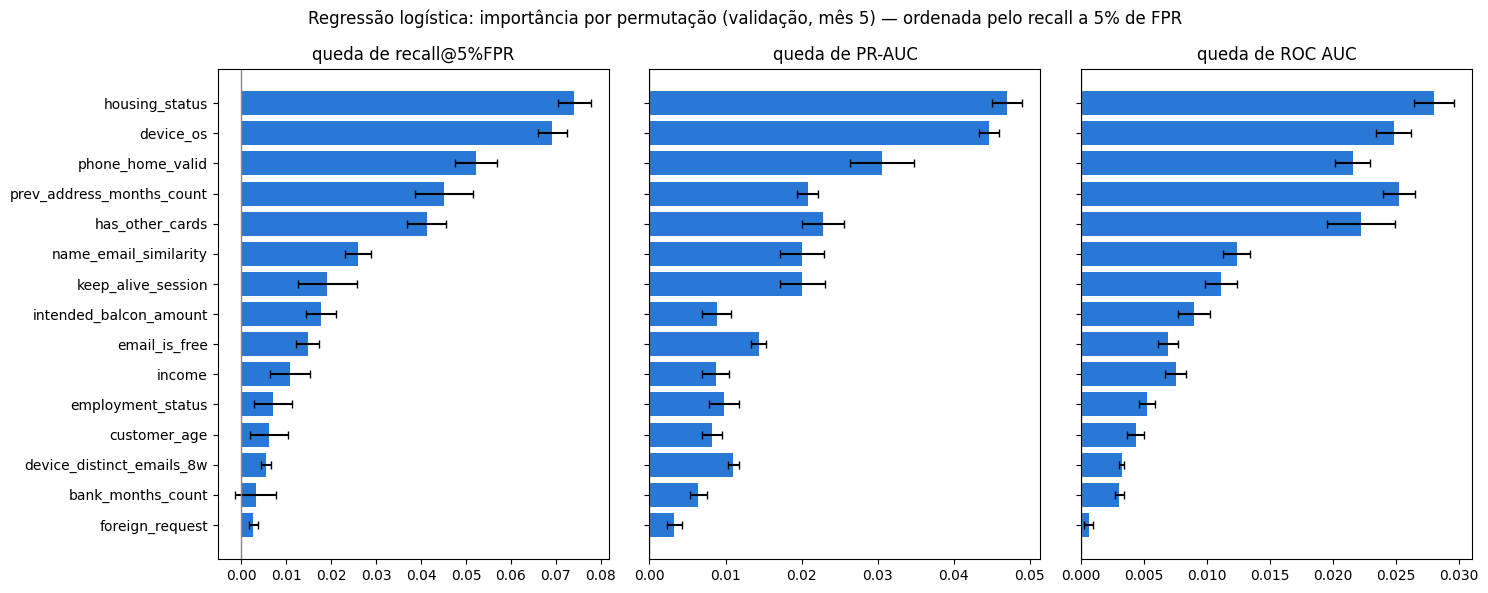

,recall@5%FPR,PR-AUC,ROC AUC
housing_status,"0,0741","0,0470","0,0280"
device_os,"0,0692","0,0447","0,0248"
phone_home_valid,"0,0522","0,0306","0,0216"
prev_address_months_count,"0,0451","0,0208","0,0253"
has_other_cards,"0,0412","0,0228","0,0223"
name_email_similarity,"0,0259","0,0200","0,0123"
keep_alive_session,"0,0191","0,0201","0,0111"
intended_balcon_amount,"0,0177","0,0088","0,0090"
email_is_free,"0,0147","0,0144","0,0069"
income,"0,0108","0,0087","0,0075"


In [13]:
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer

FIG_DIR = RAIZ / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Treina no último fold (meses 0–4) e mede a importância na validação (mês 5)
*_, (meses_tr, mes_val, idx_tr, idx_val) = gerar_folds(treino)
pipe = montar_logistica()
pipe.fit(limpar(treino.loc[idx_tr]), treino.loc[idx_tr, ALVO])
X_val = limpar(treino.loc[idx_val])
y_val = treino.loc[idx_val, ALVO]

METRICAS_IMPORTANCIA = {
    "recall@5%FPR": make_scorer(recall_a_fpr, response_method="predict_proba"),
    "PR-AUC": "average_precision",
    "ROC AUC": "roc_auc",
}

# Conferência: o scorer dá o mesmo valor que a nossa função aplicada diretamente?
via_scorer = METRICAS_IMPORTANCIA["recall@5%FPR"](pipe, X_val, y_val)
direto = recall_a_fpr(y_val, pipe.predict_proba(X_val)[:, 1])
print(f"Recall a 5% de FPR — via scorer: {via_scorer:.4f} | direto: {direto:.4f}")

imp = permutation_importance(
    pipe, X_val, y_val,
    scoring=METRICAS_IMPORTANCIA, n_repeats=5, random_state=42, n_jobs=-1,
)
importancia = pd.DataFrame(
    {m: r.importances_mean for m, r in imp.items()}, index=X_val.columns
).sort_values("recall@5%FPR", ascending=False)
desvio = pd.DataFrame(
    {m: r.importances_std for m, r in imp.items()}, index=X_val.columns
).loc[importancia.index]

top = importancia.index[:15][::-1]
fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=True)
for ax, m in zip(axes, importancia.columns):
    ax.barh(top, importancia.loc[top, m], xerr=desvio.loc[top, m], color="#2a78d6", capsize=3)
    ax.axvline(0, color="#8a8986", lw=1)
    ax.set_title(f"queda de {m}")
fig.suptitle("Regressão logística: importância por permutação (validação, mês 5) — ordenada pelo recall a 5% de FPR")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_importancia_permutacao_logistica.png", dpi=150, bbox_inches="tight")
plt.show()

importancia.head(15).style.format(precision=4, decimal=",")

**Conclusão:**

- As **cinco variáveis mais importantes são as mesmas nas três métricas** — `housing_status`, `device_os`, `phone_home_valid`, `prev_address_months_count` e `has_other_cards` —, o que torna a conclusão robusta. Todas coincidem com sinais fortes da EDA.
- No **topo do ranking** (recall a 5% de FPR, a métrica operacional), `housing_status` e `device_os` se destacam: embaralhar só `housing_status` reduz o recall em ~0,074, cerca de 15% das fraudes detectadas.
- `prev_address_months_count` cai do 2º lugar (ROC AUC) para o 4º (recall). A ausência do endereço anterior atinge 71% dos pedidos: é um sinal amplo, que ajuda a ordenar a base inteira, mas discrimina menos entre os casos mais suspeitos — diferente de grupos onde a fraude é mais concentrada, como `housing_status = BA` e `device_os = windows`.
- A importância medida pelo recall tem **mais variância** entre repetições (barras de erro maiores; a de `bank_months_count` cruza o zero), porque depende de quais casos ficam perto do ponto de corte.
- As **velocidades**, que têm o drift mais forte, quase não são usadas — bom sinal para a estabilidade do modelo.
- **`proposed_credit_limit` e `credit_risk_score` ficam fora do top 15**, apesar de serem sinais fortes na EDA (~12,5% de fraude na faixa de limite ~2.000). Duas causas:
  1. O modelo é **linear**: não captura relações em degrau ou que só aparecem no topo da escala.
  2. Variáveis **correlacionadas dividem a importância** (limite × score: ρ = 0,63).
- **Hipótese para os próximos notebooks:** modelos de árvore, que capturam relações não lineares, devem dar mais peso a essas duas variáveis — e superar este baseline.

In [14]:
DIR_REPORTS = RAIZ / "reports"

resultados = pd.concat(
    {"ingênuo (credit_risk_score)": res_ingenuo, "regressão logística": res_logistica},
    names=["modelo", "fold"],
)
resultados.to_csv(DIR_REPORTS / "resultados_02_baseline.csv", float_format="%.4f")
importancia.to_csv(DIR_REPORTS / "importancia_02_logistica.csv", float_format="%.5f")

# Conferência: relê o arquivo salvo
pd.read_csv(DIR_REPORTS / "resultados_02_baseline.csv", index_col=["modelo", "fold"])

recall@5%FPR  PR-AUC  ROC AUC
modelo                      fold                                        
ingênuo (credit_risk_score) 0–2 → 3              0.2284  0.0269   0.7063
                            0–3 → 4              0.2176  0.0319   0.6884
                            0–4 → 5              0.1928  0.0315   0.6592
                            média                0.2130  0.0301   0.6846
                            desvio padrão        0.0183  0.0028   0.0237
regressão logística         0–2 → 3              0.5402  0.1398   0.9040
                            0–3 → 4              0.5317  0.1517   0.8997
                            0–4 → 5              0.5096  0.1612   0.8845
                            média                0.5272  0.1509   0.8961
                            desvio padrão        0.0158  0.0107   0.0103

## 7. Ponto de operação: estabilidade do limiar e justiça por idade

Até aqui, o recall a 5% de FPR foi medido com o limiar escolhido na própria validação. Na prática, o limiar é definido com dados do **passado** e aplicado aos pedidos **futuros**. Duas perguntas:

1. **Estabilidade:** com o limiar fixado no treino de cada fold (5% de FPR no treino), qual é a FPR e o recall **realizados** no mês de validação?
2. **Justiça:** no limiar de 5% de FPR global, os clientes legítimos com **50 anos ou mais** são barrados com mais frequência que os mais jovens? Medimos pela **razão de FPR** entre os grupos (menor ÷ maior; 1 = igualdade), seguindo o artigo da base. Aqui o limiar é calibrado na própria validação, para isolar o efeito da idade do efeito do drift.

In [15]:
def limiar_para_fpr(y, score, fpr_alvo=FPR_ALVO):
    """Limiar acima do qual ficam `fpr_alvo` dos casos legítimos (negativos)."""
    return np.quantile(score[np.asarray(y) == 0], 1 - fpr_alvo)


def taxas(y, score, limiar):
    """FPR e recall de uma regra 'barrar se score > limiar'."""
    y = np.asarray(y)
    alerta = score > limiar
    return {"FPR": alerta[y == 0].mean(), "recall": alerta[y == 1].mean()}


linhas = []
for meses_tr, mes_val, idx_tr, idx_val in gerar_folds(treino):
    X_tr, y_tr = limpar(treino.loc[idx_tr]), treino.loc[idx_tr, ALVO].to_numpy()
    X_va, y_va = limpar(treino.loc[idx_val]), treino.loc[idx_val, ALVO].to_numpy()

    pipe = montar_logistica()
    pipe.fit(X_tr, y_tr)
    s_tr = pipe.predict_proba(X_tr)[:, 1]
    s_va = pipe.predict_proba(X_va)[:, 1]

    limiar_passado = limiar_para_fpr(y_tr, s_tr)  # o que o banco faria na prática
    limiar_ideal = limiar_para_fpr(y_va, s_va)    # referência: calibrado no próprio mês
    real = taxas(y_va, s_va, limiar_passado)
    ideal = taxas(y_va, s_va, limiar_ideal)

    mais_50 = (treino.loc[idx_val, "customer_age"] >= 50).to_numpy()
    fpr_menos_50 = taxas(y_va[~mais_50], s_va[~mais_50], limiar_ideal)["FPR"]
    fpr_mais_50 = taxas(y_va[mais_50], s_va[mais_50], limiar_ideal)["FPR"]

    linhas.append({
        "fold": f"{meses_tr[0]}–{meses_tr[-1]} → {mes_val}",
        "FPR realizada": real["FPR"],
        "recall realizado": real["recall"],
        "recall (limiar ideal)": ideal["recall"],
        "FPR < 50 anos": fpr_menos_50,
        "FPR ≥ 50 anos": fpr_mais_50,
        "razão de FPR": min(fpr_menos_50, fpr_mais_50) / max(fpr_menos_50, fpr_mais_50),
    })

operacao = pd.DataFrame(linhas).set_index("fold")
operacao.loc["média"] = operacao.mean()
operacao.to_csv(RAIZ / "reports" / "operacao_02_logistica.csv", float_format="%.4f")
operacao.style.format(precision=3, decimal=",")

,FPR realizada,recall realizado,recall (limiar ideal),FPR < 50 anos,FPR ≥ 50 anos,razão de FPR
fold,,,,,,
0–2 → 3,"0,077","0,647","0,540","0,032","0,125","0,260"
0–3 → 4,"0,061","0,582","0,532","0,034","0,123","0,273"
0–4 → 5,"0,032","0,443","0,510","0,037","0,115","0,319"
média,"0,057","0,557","0,527","0,034","0,121","0,284"


**Conclusão:**

- **Checagem:** o recall com limiar ideal (0,540 / 0,532 / 0,510) coincide com o da seção 5, calculado por outro caminho.
- **O limiar fixado no passado não se mantém:** a FPR realizada foi de 7,7%, 6,1% e 3,2% nos três folds, contra os 5% planejados. No fold 1, o modelo barrou ~54% mais clientes legítimos que o previsto; no fold 3, barrou menos e o recall caiu para 0,443. A média (5,7%) esconde essa instabilidade.
- É o **drift** chegando à operação: a distribuição dos scores muda entre meses, e o mesmo valor de corte passa a significar outra coisa. Em produção, o limiar precisaria ser **recalibrado periodicamente**, ou a regra definida como "revisar os 5% mais suspeitos de cada mês" em vez de um score fixo.
- **Justiça por idade:** no limiar de 5% de FPR global, legítimos com **50 anos ou mais são barrados ~3,5× mais** (FPR de 12,1% contra 3,4%). **Razão de FPR de 0,28**, longe da referência comum de 0,8.
- `customer_age` teve importância baixa na seção 6, e mesmo assim a desigualdade é grande: a idade influencia o score por vários caminhos (diretamente, por variáveis relacionadas e pela taxa de fraude maior no grupo). **Importância baixa não significa ausência de viés.**
- Há um dilema: a idade carrega sinal real de fraude, e equalizar a FPR entre grupos teria custo em recall. A decisão fica para o modelo final; aqui, os números servem de **régua** para comparar os próximos modelos.
- Resultados salvos em `reports/operacao_02_logistica.csv`.

## 8. Resumo

| Modelo | Recall a 5% FPR | PR-AUC | ROC AUC |
|---|---|---|---|
| Ingênuo (`credit_risk_score`) | 0,213 ± 0,018 | 0,030 ± 0,003 | 0,685 ± 0,024 |
| **Regressão logística** | **0,527 ± 0,016** | **0,151 ± 0,011** | **0,896 ± 0,010** |

*Média ± desvio padrão nos 3 folds temporais.*

| Ponto de operação (regressão logística) | Valor |
|---|---|
| FPR realizada com limiar fixado no treino | 7,7% / 6,1% / 3,2% (planejado: 5%) |
| FPR de legítimos < 50 anos vs. ≥ 50 anos | 3,4% vs. 12,1% |
| Razão de FPR por idade | 0,28 |

- **A régua do projeto é a regressão logística:** recall de 0,527 a 5% de FPR, razão de FPR por idade de 0,28.
- Pré-processamento sem vazamento: limpeza sem estado fora do `Pipeline`; mediana, padronização e one-hot ajustados só no treino de cada fold (verificado na seção 4).
- O modelo linear não aproveita relações não lineares fortes vistas na EDA (`proposed_credit_limit`, `credit_risk_score`) — motivação para os próximos notebooks.
- O drift afeta a operação: um limiar fixo não garante a FPR planejada nos meses seguintes.
- Resultados salvos em `reports/`.

**Próximo passo:** `03_preprocessamento.ipynb` — grade com todas as combinações de técnicas de pré-processamento, avaliada nos mesmos folds.